In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import time
import cv2
import numpy as np
import os

# Rastgeleliği sabitleyelim (Tekrarlanabilir sonuçlar için)
torch.manual_seed(42)

# Görüntüleri Tensor'a çevirme ve Normalizasyon (-1 ile 1 arasına çekme)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# 1. Bütün Eğitim Verisini İndir (60.000 görsel)
full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

# 2. Test Verisini İndir (10.000 görsel - Modele eğitim sırasında HİÇ gösterilmeyecek)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# 3. Eğitim verisini Train (50.000) ve Validation (10.000) olarak ikiye böl
train_size = 50000
val_size = 10000
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# DataLoader'ları oluştur (Veriyi modele 64'erli paketler halinde beslemek için)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Train Verisi: {len(train_dataset)} adet")
print(f"Validation Verisi: {len(val_dataset)} adet")
print(f"Test Verisi: {len(test_dataset)} adet")

100.0%
100.0%
100.0%
100.0%

Train Verisi: 50000 adet
Validation Verisi: 10000 adet
Test Verisi: 10000 adet


In [2]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        # 28x28 boyutundaki matrisi tek boyutlu 784 elemanlı vektöre düzleştirir
        self.flatten = nn.Flatten()
        
        # Input Layer -> Hidden Layer 1 (En az 2 hidden layer kuralı)
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu1 = nn.ReLU() # İstenilen aktivasyon fonksiyonu
        
        # Hidden Layer 1 -> Hidden Layer 2
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()
        
        # Hidden Layer 2 -> Output Layer (10 Sınıf: 0-9 arası rakamlar)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        out = self.fc3(x)
        return out

# Modeli oluştur ve kullanılacak cihazı (CPU/GPU) belirle
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MLP().to(device)

print("Kullanılan Cihaz:", device)
print("Model Mimarisi Başarıyla Oluşturuldu:")
print(model)

Kullanılan Cihaz: cpu
Model Mimarisi Başarıyla Oluşturuldu:
MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)


In [3]:
# Ödevde istenen Sınıflandırma Loss (Kayıp) fonksiyonu ve Optimizer (Adam)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

print("Eğitim Başlıyor, bu işlem bilgisayar hızına göre 1-2 dakika sürebilir...\n")
start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    # 1. Training (Eğitim) Aşaması
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad() # Gradienleri sıfırla
        outputs = model(images) # İleri yayılım (Forward pass)
        loss = criterion(outputs, labels) # Kaybı hesapla
        loss.backward() # Geri yayılım (Backward pass)
        optimizer.step() # Ağırlıkları güncelle
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = 100 * correct_train / total_train
    
    # 2. Validation (Doğrulama) Aşaması
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad(): # Validation sırasında ağırlıklar güncellenmez (gradyan hesaplanmaz)
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    epoch_val_loss = val_loss / len(val_loader)
    epoch_val_acc = 100 * correct_val / total_val
    
    # Grafikler için değerleri listelere kaydet
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.2f}%")

end_time = time.time()
training_time = end_time - start_time
print(f"\nEğitim Tamamlandı! Toplam Eğitim Süresi: {training_time:.2f} saniye")




Eğitim Başlıyor, bu işlem bilgisayar hızına göre 1-2 dakika sürebilir...

Epoch [1/10] | Train Loss: 0.4216 - Train Acc: 87.51% | Val Loss: 0.2746 - Val Acc: 91.87%
Epoch [2/10] | Train Loss: 0.2112 - Train Acc: 93.60% | Val Loss: 0.2195 - Val Acc: 93.26%
Epoch [3/10] | Train Loss: 0.1565 - Train Acc: 95.32% | Val Loss: 0.1682 - Val Acc: 95.09%
Epoch [4/10] | Train Loss: 0.1280 - Train Acc: 96.06% | Val Loss: 0.1513 - Val Acc: 95.59%
Epoch [5/10] | Train Loss: 0.1049 - Train Acc: 96.70% | Val Loss: 0.1521 - Val Acc: 95.26%
Epoch [6/10] | Train Loss: 0.0904 - Train Acc: 97.19% | Val Loss: 0.1246 - Val Acc: 96.38%
Epoch [7/10] | Train Loss: 0.0837 - Train Acc: 97.40% | Val Loss: 0.1162 - Val Acc: 96.51%
Epoch [8/10] | Train Loss: 0.0740 - Train Acc: 97.68% | Val Loss: 0.1192 - Val Acc: 96.39%
Epoch [9/10] | Train Loss: 0.0639 - Train Acc: 97.96% | Val Loss: 0.1242 - Val Acc: 96.54%
Epoch [10/10] | Train Loss: 0.0600 - Train Acc: 98.13% | Val Loss: 0.1169 - Val Acc: 96.46%

Eğitim Tamamla

Test Seti Doğruluğu (Test Accuracy): 96.90%



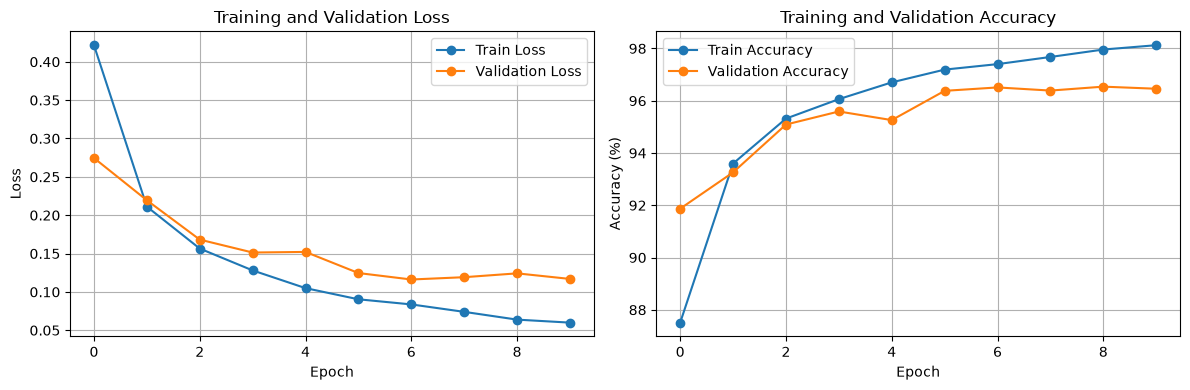

In [4]:
# 1. Test Verisi ile Modelin Son Başarısını Ölçme
model.eval()
correct_test = 0
total_test = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()

test_accuracy = 100 * correct_test / total_test
print(f"Test Seti Doğruluğu (Test Accuracy): {test_accuracy:.2f}%\n")

# 2. Loss (Kayıp) ve Accuracy (Doğruluk) Grafiklerini Çizdirme
plt.figure(figsize=(12, 4))

# Loss Grafiği
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy Grafiği
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy', marker='o')
plt.plot(val_accuracies, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Yapay Zeka Destekli Otomatik Odaklanma ile Test Başlıyor...



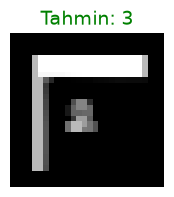

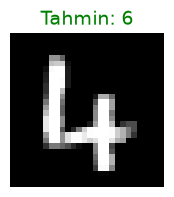

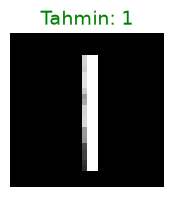

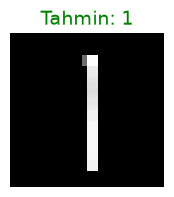

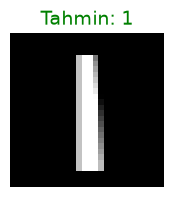

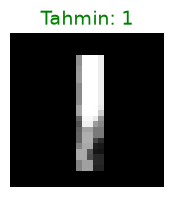

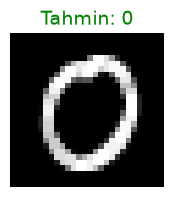

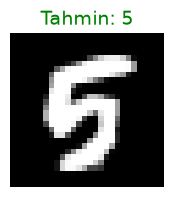

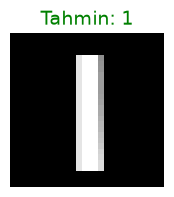

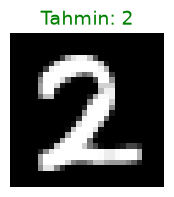

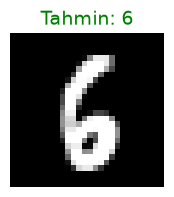

In [11]:
import cv2
import numpy as np

def predict_custom_digit_v3(image_path, model, device):
    # 1. Görüntüyü Oku
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Hata: {image_path} okunamadı.")
        return

    # 2. Kağıttaki gölgeleri yok et ve yazıyı bembeyaz (arka planı zifiri siyah) yap
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # 3. Yazının (rakamın) kağıt üzerindeki koordinatlarını bul
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        print(f"{image_path} içinde rakam tespit edilemedi!")
        return

    # En büyük şekli (bizim rakamımızı) seç ve etrafından kırp
    c = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)
    digit = thresh[y:y+h, x:x+w]

    # 4. MNIST Formatına Uyarlama (Rakamı kare bir çerçevenin tam ortasına oturtma)
    max_side = max(w, h)
    pad_y = (max_side - h) // 2
    pad_x = (max_side - w) // 2
    
    # Kenarlara MNIST'teki gibi ekstra siyah boşluk (margin) ekle
    margin = int(max_side * 0.2) 
    padded = cv2.copyMakeBorder(digit, pad_y + margin, pad_y + margin, 
                                pad_x + margin, pad_x + margin, 
                                cv2.BORDER_CONSTANT, value=0)

    # 5. Tam 28x28 boyutuna getir ve çizgileri belirginleştir
    img_resized = cv2.resize(padded, (28, 28), interpolation=cv2.INTER_AREA)
    kernel = np.ones((2, 2), np.uint8)
    img_dilated = cv2.dilate(img_resized, kernel, iterations=1)

    # 6. Tensora Çevir ve Tahmin Yap
    img_normalized = (img_dilated / 255.0 - 0.5) / 0.5
    img_tensor = torch.tensor(img_normalized, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        _, predicted = torch.max(output.data, 1)

    # 7. Sonucu Göster
    plt.figure(figsize=(2,2))
    plt.imshow(img_dilated, cmap='gray')
    plt.title(f"Tahmin: {predicted.item()}", fontsize=14, color='green')
    plt.axis('off')
    plt.show()

# 24120205026 numaralı öğrencinin fotoğrafları
resimler = [
    "rakam_2_ilk.jpg", "rakam_4.jpg", "rakam_1.jpg", "rakam_2_ikinci.jpg", 
    "rakam_0_ilk.jpg", "rakam_2_ucuncu.jpg", "rakam_0_ikinci.jpg", 
    "rakam_5.jpg", "rakam_0_ucuncu.jpg", "rakam_2_dorduncu.jpg", "rakam_6.jpg"
]

print("Yapay Zeka Destekli Otomatik Odaklanma ile Test Başlıyor...\n")
for resim in resimler:
    predict_custom_digit_v3(resim, model, device)